<a href="https://colab.research.google.com/github/andresjaimes2004/tesis-desercion/blob/main/notebooks/03_modelado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Modelado (OE2)

Fase 4 de CRISP-DM. Entrena los cinco modelos base del anteproyecto con tres estrategias frente al desbalance (sin balanceo, SMOTE-NC y ponderación de clases), en los tres momentos de predicción y con dos conjuntos de variables. Todo se evalúa con validación cruzada estratificada de 5 pliegues **sobre el entrenamiento**; el conjunto de prueba no se usa en este cuaderno.

**Tiempo estimado en Colab: entre 10 y 20 minutos.** No cierres la pestaña mientras corre.

In [1]:
# Preparar el entorno (igual que en el cuaderno 00)
import os, sys
REPO_URL = "https://github.com/andresjaimes2004/tesis-desercion.git"
REPO_DIR = "/content/tesis-desercion"
if "google.colab" in sys.modules and not os.path.exists(REPO_DIR):
    !git clone -q {REPO_URL} {REPO_DIR}
if os.path.exists(REPO_DIR):
    os.chdir(REPO_DIR)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%pip install -q -r requirements.txt

In [2]:
import warnings
warnings.filterwarnings("ignore", message="Unknown solver options")  # aviso interno de SciPy

import pandas as pd
from src import config, plots, prep, models
from src.data import load_raw, binarize_target
from src.utils import set_seed

set_seed()
pd.set_option("display.max_columns", 50)
df = prep.add_no_enrollment_flags(binarize_target(load_raw()))
idx_train, idx_test = prep.load_split()      # la misma partición de la Fase 3
print("Entrenamiento:", len(idx_train), "| Prueba (no se usa aquí):", len(idx_test))

Entrenamiento: 3539 | Prueba (no se usa aquí): 885


## 1. Validación cruzada de los modelos base

5 modelos × 3 estrategias × 3 momentos × 2 conjuntos de variables = 90 combinaciones, cada una con 5 pliegues. Cada línea impresa es una combinación terminada.

In [3]:
conjuntos = {"completo": (), "sin no significativas": prep.non_significant()}
pliegues = models.cv_base_models(df, idx_train, feature_sets=conjuntos)
pliegues.to_csv(config.REPORTS / "modelos_base_pliegues.csv", index=False, encoding="utf-8-sig")
resumen = models.summarize(pliegues)
resumen.to_csv(config.REPORTS / "modelos_base_resumen.csv", index=False, encoding="utf-8-sig")

matricula  | completo               | Regresión logística | sin balanceo | sens=0.521 auc=0.817 (1 s)
matricula  | completo               | Regresión logística | SMOTE-NC     | sens=0.660 auc=0.795 (7 s)
matricula  | completo               | Regresión logística | ponderación  | sens=0.686 auc=0.817 (1 s)
matricula  | completo               | Árbol de decisión   | sin balanceo | sens=0.544 auc=0.655 (0 s)
matricula  | completo               | Árbol de decisión   | SMOTE-NC     | sens=0.567 auc=0.652 (3 s)
matricula  | completo               | Árbol de decisión   | ponderación  | sens=0.528 auc=0.655 (0 s)
matricula  | completo               | Random Forest       | sin balanceo | sens=0.485 auc=0.819 (11 s)
matricula  | completo               | Random Forest       | SMOTE-NC     | sens=0.604 auc=0.811 (16 s)
matricula  | completo               | Random Forest       | ponderación  | sens=0.475 auc=0.818 (11 s)
matricula  | completo               | XGBoost             | sin balanceo | sens

## 2. Matriz comparativa (cierre del 2.º semestre, conjunto completo)

In [4]:
cols = ["modelo", "estrategia"] + [f"{m}_media" for m in models.METRICS]
resumen.query("momento == 'semestre_2' and conjunto == 'completo'")[cols].round(3)

,modelo,estrategia,exactitud_media,sensibilidad_media,precision_media,f1_media,auc_roc_media,brier_media
60,Regresión logística,sin balanceo,0.877,0.740,0.858,0.794,0.918,0.095
61,Regresión logística,SMOTE-NC,0.859,0.795,0.773,0.784,0.912,0.107
62,Regresión logística,ponderación,0.858,0.811,0.762,0.786,0.918,0.105
63,Árbol de decisión,sin balanceo,0.803,0.714,0.687,0.700,0.780,0.197
64,Árbol de decisión,SMOTE-NC,0.773,0.709,0.633,0.668,0.756,0.227
65,Árbol de decisión,ponderación,0.800,0.689,0.689,0.688,0.770,0.200
66,Random Forest,sin balanceo,0.868,0.703,0.863,0.774,0.915,0.100
67,Random Forest,SMOTE-NC,0.867,0.777,0.804,0.790,0.913,0.105
68,Random Forest,ponderación,0.871,0.698,0.874,0.776,0.915,0.101
69,XGBoost,sin balanceo,0.872,0.738,0.844,0.787,0.916,0.100


## 3. ¿Conjunto completo o reducido?

Criterio de parsimonia fijado antes de ver resultados: si el AUC-ROC del conjunto sin las 7 variables no significativas no queda más de un error estándar por debajo del completo, se prefiere el reducido por ser más simple.

In [5]:
comparacion_conjuntos = models.feature_set_comparison(resumen)
comparacion_conjuntos.to_csv(config.REPORTS / "comparacion_conjuntos.csv", index=False, encoding="utf-8-sig")
comparacion_conjuntos.round(4)

,momento,modelo,auc_completo,ee_completo,auc_reducido,diferencia,reducido_aceptable
0,matricula,Random Forest,0.8190,0.0059,0.8160,-0.0030,True
1,matricula,Regresión logística,0.8170,0.0091,0.8163,-0.0007,True
2,matricula,SVM,0.8194,0.0087,0.8181,-0.0012,True
3,matricula,XGBoost,0.8023,0.0076,0.8008,-0.0015,True
4,matricula,Árbol de decisión,0.6554,0.0051,0.6586,0.0032,True
5,semestre_1,Random Forest,0.8964,0.0035,0.8942,-0.0022,True
6,semestre_1,Regresión logística,0.9021,0.0066,0.8977,-0.0044,True
7,semestre_1,SVM,0.9000,0.0048,0.8961,-0.0040,True
8,semestre_1,XGBoost,0.8966,0.0043,0.8920,-0.0046,False
9,semestre_1,Árbol de decisión,0.7439,0.0036,0.7479,0.0040,True


## 4. Modelos con mayor potencial

Mejor estrategia de cada modelo según el AUC-ROC, que no depende del umbral de decisión (el umbral se ajusta en la Fase 5).

In [6]:
ranking = models.ranking(resumen)
ranking.to_csv(config.REPORTS / "ranking_modelos.csv", index=False, encoding="utf-8-sig")
ranking[cols].round(3)

,modelo,estrategia,exactitud_media,sensibilidad_media,precision_media,f1_media,auc_roc_media,brier_media
0,Regresión logística,sin balanceo,0.877,0.740,0.858,0.794,0.918,0.095
1,XGBoost,sin balanceo,0.872,0.738,0.844,0.787,0.916,0.100
2,SVM,ponderación,0.864,0.791,0.788,0.789,0.916,0.099
3,Random Forest,sin balanceo,0.868,0.703,0.863,0.774,0.915,0.100
4,Árbol de decisión,sin balanceo,0.803,0.714,0.687,0.700,0.780,0.197


## 5. Figuras

PosixPath('/content/tesis-desercion/reports/figures/fig_07_auc_por_momento.png')

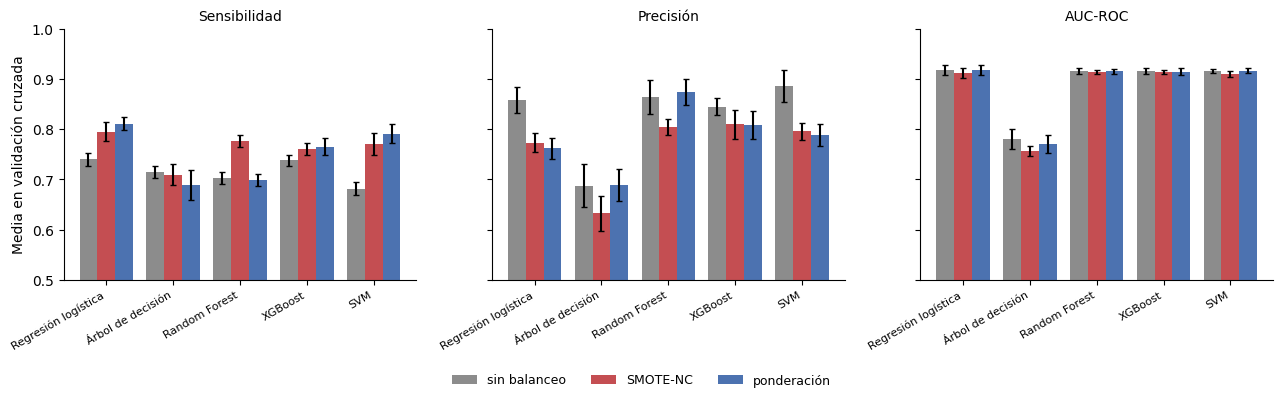

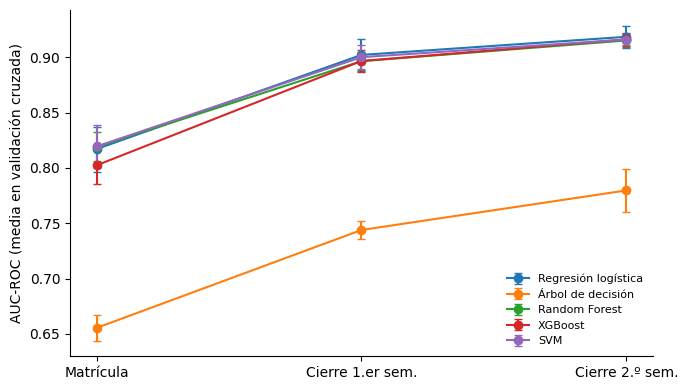

In [7]:
plots.strategy_comparison(resumen)
plots.moments_comparison(resumen)

## 6. Resumen para el documento

Ejecutar esta celda y enviar su salida completa.

In [8]:
pd.set_option("display.width", 250)
m = ["modelo", "estrategia", "exactitud_media", "sensibilidad_media", "sensibilidad_de", "precision_media",
     "f1_media", "auc_roc_media", "auc_roc_de", "brier_media"]
for mom in config.MOMENTS:
    print(f"\nMATRIZ {mom.upper()} (conjunto completo):")
    print(resumen.query("momento == @mom and conjunto == 'completo'")[m].round(3).to_string(index=False))
print("\nCOMPLETO VS. REDUCIDO (AUC-ROC):")
print(comparacion_conjuntos.round(4).to_string(index=False))
print("\nRANKING SEMESTRE 2:")
print(ranking[m].round(3).to_string(index=False))


MATRIZ MATRICULA (conjunto completo):
             modelo   estrategia  exactitud_media  sensibilidad_media  sensibilidad_de  precision_media  f1_media  auc_roc_media  auc_roc_de  brier_media
Regresión logística sin balanceo            0.788               0.521            0.021            0.743     0.612          0.817       0.020        0.151
Regresión logística     SMOTE-NC            0.734               0.660            0.022            0.575     0.614          0.795       0.012        0.176
Regresión logística  ponderación            0.747               0.686            0.010            0.594     0.636          0.817       0.021        0.169
  Árbol de decisión sin balanceo            0.695               0.544            0.012            0.525     0.534          0.655       0.011        0.305
  Árbol de decisión     SMOTE-NC            0.683               0.567            0.021            0.505     0.535          0.652       0.012        0.317
  Árbol de decisión  ponderación     

## 7. Guardar resultados en GitHub

La siguiente celda empaqueta la carpeta `reports/` en `reports_fase4.zip`. Descárgalo desde el panel de archivos, descomprímelo y sube su contenido a la carpeta `reports` del repositorio con el mensaje `Fase 4: modelado`. Luego guarda este cuaderno con Archivo > Guardar una copia en GitHub.

In [9]:
!cd /content/tesis-desercion && zip -qr /content/reports_fase4.zip reports && echo "Listo: /content/reports_fase4.zip"

Listo: /content/reports_fase4.zip
